In [2]:
%pip install pandas numpy matplotlib seaborn scikit-learn xgboost

import pandas as pd
import numpy as np

# 1. Veri setini oku
df = pd.read_csv('E-commerce_Customer_Churn_2026.csv')

# 2. Veri setinin boyutunu ve ilk 5 satırını kontrol et
print("Veri Seti Boyutu (Satır, Sütun):", df.shape)
print("\nİlk 5 Satır:")
display(df.head())

# 3. Data Leakage (Veri Sızıntısı) yapacak sütunları listeden çıkar
leakage_columns = [
    'churn_id', 'customer_id', 'churn_date', 'days_since_churn', 
    'churn_reason', 'churn_category', 'churn_risk_score', 
    'churn_probability', 'predicted_churn', 'churn_risk_category',
    'churn_revenue_impact_usd', 'retention_probability'
]

df_clean = df.drop(columns=leakage_columns)

print("\nTemizleme Sonrası Kalan Sütun Sayısı:", df_clean.shape[1])


[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.
Veri Seti Boyutu (Satır, Sütun): (50000, 48)

İlk 5 Satır:


,churn_id,customer_id,customer_segment,customer_country,customer_city,is_churned,churn_flag,churn_date,days_since_churn,churn_reason,...,customer_retention_cost_usd,recovery_revenue_usd,dataset_year,churn_rate_indicator,customer_value_category,churn_risk_category,churn_revenue_impact_usd,customer_health_score,customer_health_category,retention_probability
0,CHURN-000001,CUST-020712,Consumer,Australia,Brisbane,Yes,1,2026-05-18 00:00:00,23,Found Alternative,...,29.33,346.60,2026,Medium,High Value,Medium,10351.348,75,Good,0.10
1,CHURN-000002,CUST-044206,Small Business,Saudi Arabia,Khobar,No,0,Not Applicable,0,Not Applicable,...,49.22,403.14,2026,Low,High Value,Low,0.000,100,Excellent,0.66
2,CHURN-000003,CUST-024093,Small Business,Mexico,Leon,No,0,Not Applicable,0,Not Applicable,...,198.06,4.20,2026,Low,High Value,Low,0.000,100,Excellent,0.76
3,CHURN-000004,CUST-037777,Enterprise,Saudi Arabia,Jeddah,No,0,Not Applicable,0,Not Applicable,...,190.31,222.46,2026,Low,High Value,Very Low,0.000,100,Excellent,0.98
4,CHURN-000005,CUST-016248,Premium,Pakistan,Multan,Yes,1,2026-05-28 00:00:00,7,Poor Customer Service,...,26.49,489.02,2026,Medium,High Value,Medium,14212.088,80,Good,0.10



Temizleme Sonrası Kalan Sütun Sayısı: 36


In [4]:
# 1. Eksik Değerleri (Null/NaN) Kontrol Et
print("Eksik Değer İçeren Sütunlar:")
null_summary = df_clean.isnull().sum()
print(null_summary[null_summary > 0])

# Sayısal eksik verileri medyan ile doldur
num_cols = df_clean.select_dtypes(include=['float64', 'int64']).columns
for col in num_cols:
    if df_clean[col].isnull().sum() > 0:
        df_clean[col] = df_clean[col].fillna(df_clean[col].median())

# Kategorik eksik verileri en sık tekrar eden değer (mode) ile doldur
cat_cols = df_clean.select_dtypes(include=['object']).columns
for col in cat_cols:
    if df_clean[col].isnull().sum() > 0:
        df_clean[col] = df_clean[col].fillna(df_clean[col].mode()[0])

print("\nEksik Veriler Temizlendi! Kalan Eksik Veri Sayısı:", df_clean.isnull().sum().sum())

# 2. Metinsel (Kategorik) Verileri Sayısallaştırma (One-Hot Encoding)
# Target (hedef) değişkenimiz haricindeki kategorik sütunları dönüştürüyoruz
target_col = 'is_churned'
features = df_clean.drop(columns=[target_col, 'churn_flag'])

# One-Hot Encoding uygula
features_encoded = pd.get_dummies(features, drop_first=True)

# Temizlenmiş ve işlenmiş veriyi yeni bir DataFrame olarak birleştir
df_final = pd.concat([features_encoded, df_clean[['churn_flag']]], axis=1)

print("\n--- İŞLEM TAMAMLANDI ---")
print("Model Eğitimi İçin Hazır Olan Veri Boyutu (Satır, Sütun):", df_final.shape)
display(df_final.head())

Eksik Değer İçeren Sütunlar:
Series([], dtype: int64)

Eksik Veriler Temizlendi! Kalan Eksik Veri Sayısı: 0

--- İŞLEM TAMAMLANDI ---
Model Eğitimi İçin Hazır Olan Veri Boyutu (Satır, Sütun): (50000, 226)


C:\Users\fgulf\AppData\Local\Temp\ipykernel_7152\2426950396.py:13: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df_clean.select_dtypes(include=['object']).columns


,customer_age_months,total_spend_usd,avg_order_value_usd,num_purchases,satisfaction_score,support_tickets,returns_count,days_since_last_purchase,customer_lifetime_value_usd,support_interactions,...,is_high_risk_customer_Yes,churn_rate_indicator_Low,churn_rate_indicator_Medium,customer_value_category_Low Value,customer_value_category_Medium Value,customer_value_category_Very Low Value,customer_health_category_Fair,customer_health_category_Good,customer_health_category_Poor,churn_flag
0,33,25878.37,892.36,29,3,0,9,35,29849.63,1,...,False,False,True,False,False,False,False,True,False,1
1,55,25992.52,1039.70,25,2,6,3,3,30007.71,1,...,False,True,False,False,False,False,False,False,False,0
2,45,45248.32,9049.66,5,5,7,7,158,51527.18,7,...,False,True,False,False,False,False,False,False,False,0
3,7,31902.68,1329.28,24,5,8,3,46,39139.58,1,...,False,True,False,False,False,False,False,False,False,0
4,12,35530.22,755.96,47,1,15,4,124,34506.94,1,...,False,False,True,False,False,False,False,True,False,1


C:\Users\fgulf\AppData\Local\Temp\ipykernel_7152\528193525.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_clean, x='is_churned', palette='Set2')
C:\Users\fgulf\AppData\Local\Temp\ipykernel_7152\528193525.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x='is_churned', y='support_tickets', palette='Set2')
C:\Users\fgulf\AppData\Local\Temp\ipykernel_7152\528193525.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x='is_churned', y='satisfaction_score', palette='Set2')


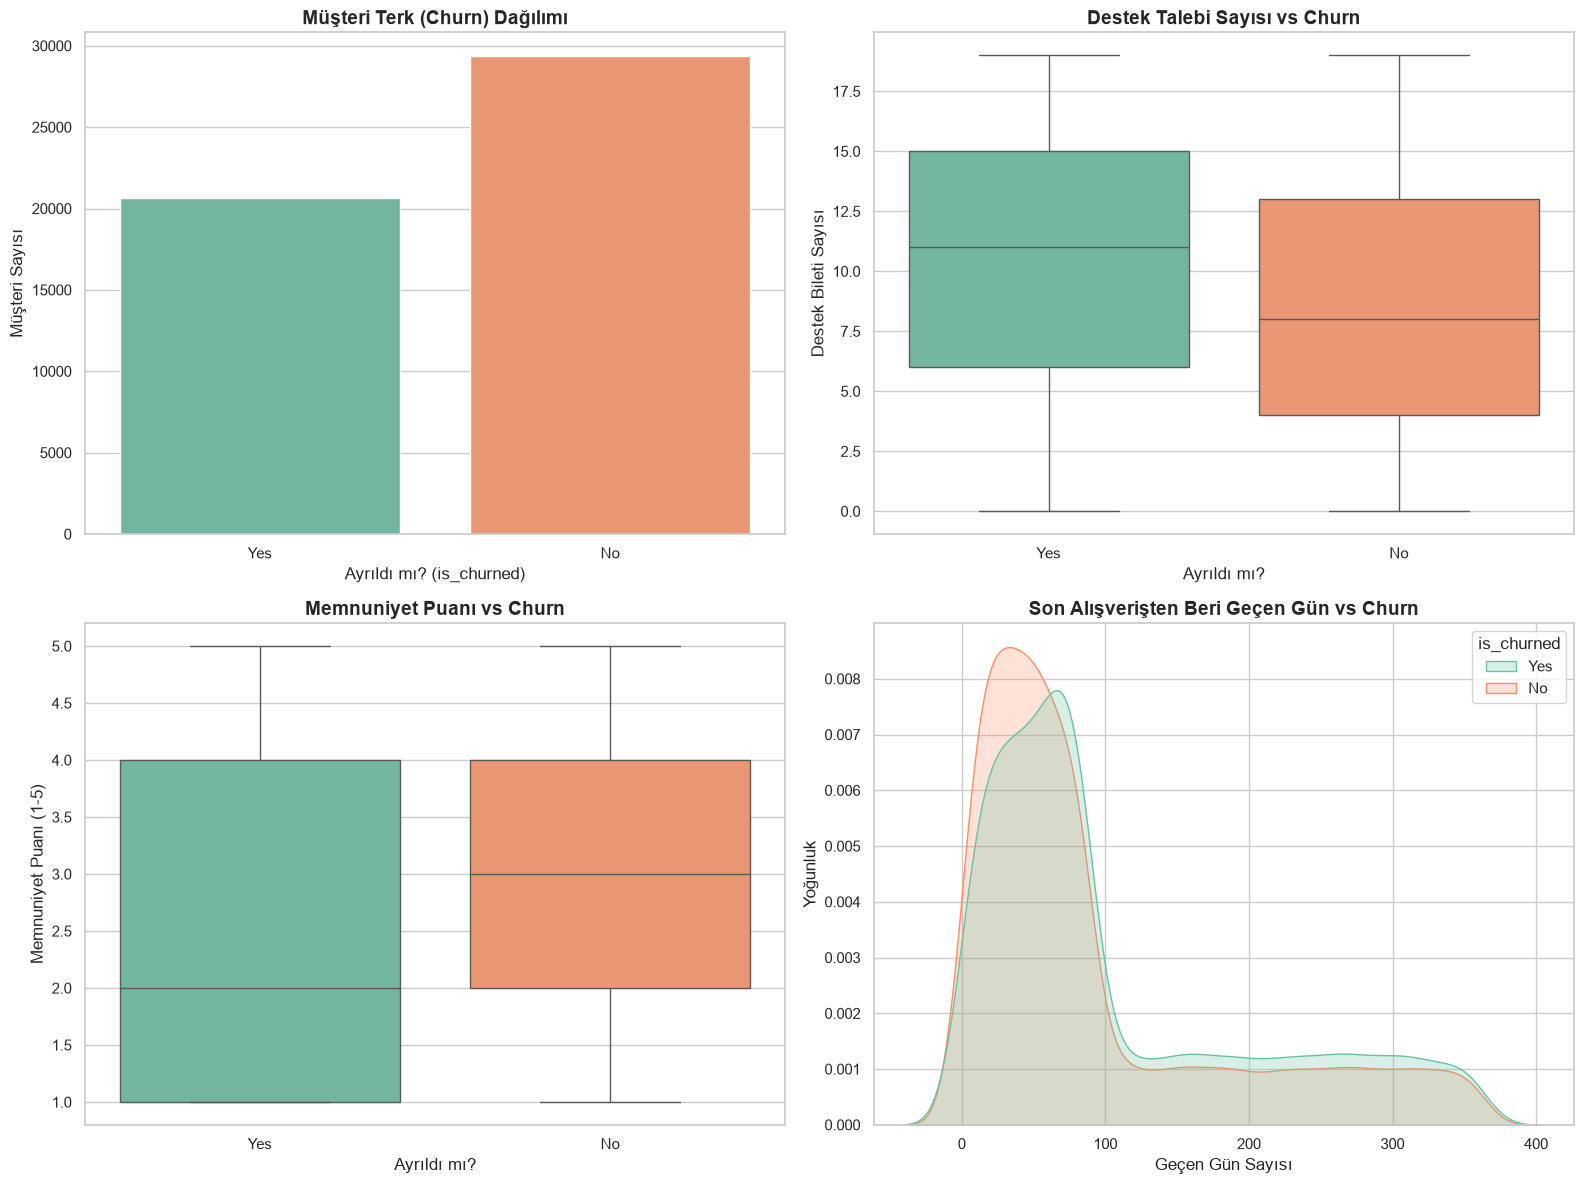

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

# Grafik stilini ayarla
sns.set_theme(style="whitegrid")
plt.figure(figsize=(16, 12))

# 1. Churn Oranı Dağılımı (Kaç müşteri kaldı, kaçı gitti?)
plt.subplot(2, 2, 1)
sns.countplot(data=df_clean, x='is_churned', palette='Set2')
plt.title('Müşteri Terk (Churn) Dağılımı', fontsize=14, fontweight='bold')
plt.xlabel('Ayrıldı mı? (is_churned)')
plt.ylabel('Müşteri Sayısı')

# 2. Destek Bileti Sayısının Churn Üzerindeki Etkisi
plt.subplot(2, 2, 2)
sns.boxplot(data=df_clean, x='is_churned', y='support_tickets', palette='Set2')
plt.title('Destek Talebi Sayısı vs Churn', fontsize=14, fontweight='bold')
plt.xlabel('Ayrıldı mı?')
plt.ylabel('Destek Bileti Sayısı')

# 3. Müşteri Memnuniyet Puanı (Satisfaction Score) Dağılımı
plt.subplot(2, 2, 3)
sns.boxplot(data=df_clean, x='is_churned', y='satisfaction_score', palette='Set2')
plt.title('Memnuniyet Puanı vs Churn', fontsize=14, fontweight='bold')
plt.xlabel('Ayrıldı mı?')
plt.ylabel('Memnuniyet Puanı (1-5)')

# 4. Son Alışverişten Bu Yana Geçen Gün Sayısı (Recency)
plt.subplot(2, 2, 4)
sns.kdeplot(data=df_clean, hue='is_churned', x='days_since_last_purchase', common_norm=False, palette='Set2', fill=True)
plt.title('Son Alışverişten Beri Geçen Gün vs Churn', fontsize=14, fontweight='bold')
plt.xlabel('Geçen Gün Sayısı')
plt.ylabel('Yoğunluk')

plt.tight_layout()
plt.show()

In [7]:
# Temizlenmiş nihai veriyi bilgisayara kaydet
df_final.to_csv('cleaned_data.csv', index=False)